# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Lin 2020's PDAC malignant manifold is **non-branching**: the developmental signatures
collapse onto a **single dominant axis** — posterior-somitogenesis (pSom) high over the
ductal body opposed to neural-crest (Crest) at a terminal end — rather than a hub radiating
to discrete subtypes with cross-repression. Gastrulation (Gast) is only weakly structured
(an *early* embryonic programme, largely spent in this late epithelial lineage). The correct
topology is therefore a **principal curve** (ElPiGraph, non-branching by construction) fit on
the *joint* embedding — **not** a re-embedding (re-embedding an anisotropic compartment
fabricates folds; the Kürten §4 failure mode).

**Scope decision (derived, not inherited) — the cell-cycle confound.** The two lobes here
are a **proliferation split** (Cycling 26% vs Ductal-body 4%), and the Crest terminus is
enriched in the Cycling lobe — exactly the confound the Kürten 2021 evaluation flagged
(a module driven by proliferation, not development). We test it rigorously: (i) the module
gene sets carry **almost no cell-cycle genes** (Gast 0/81, Crest 0/104, pSom 2/98 overlap
with the Regev/Tirosh S+G2M panels), so scores cannot be mechanically driven by cycling;
(ii) the pSom↔Crest spatial anti-correlation **survives within the non-cycling Ductal-body
lobe alone** (r ≈ −0.39, essentially unchanged from the whole-manifold −0.40). The axis is
therefore genuine and spans both lobes — the **Zhou 2020 precedent** (cell cycle defines the
lobes but is orthogonal to the developmental identity of the axis), *not* the Kürten case
(confounded module → scope out). We keep the **whole manifold** and carry an explicit
proliferation caveat (pseudotime correlates moderately with cycling). Deliverable:
`manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Cells keep their *original joint embedding coordinates* — no re-embedding. The three
embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against the
shared **union** control pool and graph-smoothed (kNN averaging, 3 passes) to read geography
rather than 10x per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
u,s,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 10304 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 2.57
Gast: 78/81 genes present
pSom: 89/98 genes present
Crest: 101/104 genes present
raw module means (honest readout): {'Gast': -0.0083, 'pSom': 0.0463, 'Crest': -0.0055}


### Scope decision — the cell-cycle confound test (Kürten vs Zhou fork)
The decisive check for this dataset. The lobes split by **cell cycle**, and Crest enriches
the Cycling lobe, so we must prove the developmental axis is not a proliferation artifact
before keeping the whole manifold. Three facts settle it: (i) the module gene sets are
**cell-cycle-free** (near-zero overlap with the S/G2M panels); (ii) the pSom→Crest
anti-correlation **holds within the non-cycling lobe alone**; (iii) module↔cell-cycle-score
correlations are modest (|rho| ≤ 0.21). The proliferation split is therefore orthogonal to
the developmental *identity* of the axis (Zhou 2020), so the whole manifold is the honest
developmental object. We nonetheless record the caveat that the Crest terminus is
proliferation-enriched, to carry into 03/04.

In [4]:
# cell-cycle gene overlap with each module (Regev/Tirosh S + G2M panels)
s_genes=['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','MLF1IP','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes=['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
cc = set(s_genes)|set(g2m_genes)
for src,l in label.items():
    ov = set(feat[src]) & cc
    print(f'{l}: {feat[src].size} genes, {len(ov)} overlap cell-cycle panels {sorted(ov)}')
sc.tl.score_genes_cell_cycle(adata, s_genes=[g for g in s_genes if g in adata.var_names],
                             g2m_genes=[g for g in g2m_genes if g in adata.var_names])
print('\nmodule vs cell-cycle score (Spearman rho, whole manifold):')
for m in ['Gast','pSom','Crest']:
    rs,_ = spearmanr(adata.obs['S_score'], adata.obs[m]); rg,_ = spearmanr(adata.obs['G2M_score'], adata.obs[m])
    print(f'  {m}: vs S rho={rs:+.2f} | vs G2M rho={rg:+.2f}')
print('\nsmoothed pSom vs Crest anti-correlation:')
print('  whole manifold: r =', round(np.corrcoef(adata.obs['pSom_sm'], adata.obs['Crest_sm'])[0,1], 2))
db = adata.obs['compartment']=='Ductal-body'
sub_db = adata[db].copy()
sc.pp.neighbors(sub_db, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
Adb = (sub_db.obsp['connectivities']>0).astype(float); Adb = Adb + sp.eye(Adb.shape[0])
Adb = sp.diags(1/np.array(Adb.sum(1)).ravel()) @ Adb
Sdb = sub_db.obs[['pSom','Crest']].values.copy()
for _ in range(3): Sdb = Adb @ Sdb
print('  non-cycling Ductal-body lobe only: r =', round(np.corrcoef(Sdb[:,0], Sdb[:,1])[0,1], 2),
      '-> axis survives without the cycling lobe')
print('-> developmental axis is genuine and spans both lobes; keep whole manifold (Zhou 2020 precedent).')
sub = adata   # whole manifold is the trajectory object

Gast: 81 genes, 0 overlap cell-cycle panels []
pSom: 98 genes, 2 overlap cell-cycle panels ['RRM2', 'UBE2C']
Crest: 104 genes, 0 overlap cell-cycle panels []

module vs cell-cycle score (Spearman rho, whole manifold):
  Gast: vs S rho=-0.03 | vs G2M rho=-0.10
  pSom: vs S rho=+0.07 | vs G2M rho=+0.21
  Crest: vs S rho=+0.15 | vs G2M rho=+0.18

smoothed pSom vs Crest anti-correlation:
  whole manifold: r = -0.38
  non-cycling Ductal-body lobe only: r = -0.4 -> axis survives without the cycling lobe
-> developmental axis is genuine and spans both lobes; keep whole manifold (Zhou 2020 precedent).


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio
> 1 (minimum distance between graph-non-adjacent nodes, in units of median edge length)
certifies the curve does not fold back on itself. `epg_mu=100` is strong bending
regularisation, keeping the arc smooth. Node count is checked across 15/20/30 for stability.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

for Nodes in [15, 20, 30]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(sub, Nodes=Nodes, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(sub)
    print(f'Nodes={Nodes}: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'committed Nodes=20 -> {tips} tips, {forks} forks, self-approach {sa:.2f}')
assert forks == 0 and sa > 1, 'topology check failed'


Nodes=15: 2 tips, 0 forks | fold self-approach ratio = 2.99 (>1 = fold-free)
Nodes=20: 2 tips, 0 forks | fold self-approach ratio = 2.98 (>1 = fold-free)
Nodes=30: 2 tips, 0 forks | fold self-approach ratio = 2.96 (>1 = fold-free)
committed Nodes=20 -> 2 tips, 0 forks, self-approach 2.98


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental
origin (somitogenesis-high ductal body). Pseudotime then flows to the neural-crest terminus.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(),
                sub.obs['Crest_sm'][m].mean(), sub.obs['cycling'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f} cycling={info[tp][3]:.2f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={p:.1e}')
g2m = pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
print(f'proliferation caveat: cycling score vs pseudotime rho = {spearmanr(cyc, t)[0]:+.2f} '
      f'(Crest terminus is proliferation-enriched; axis identity still developmental per confound test)')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')

tip 0: Gast=-0.0069 pSom=+0.0527 Crest=-0.0080 cycling=0.01
tip 2: Gast=-0.0095 pSom=+0.0345 Crest=+0.0022 cycling=0.31
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.238 p=4.6e-133
  pSom_sm: rho=-0.593 p=0.0e+00
  Crest_sm: rho=+0.315 p=7.9e-237
proliferation caveat: cycling score vs pseudotime rho = +0.42 (Crest terminus is proliferation-enriched; axis identity still developmental per confound test)
Neural-crest-high decile mean pseudotime = 0.82
Somitogenesis-high decile mean pseudotime = 0.27
Gastrulation-high decile mean pseudotime = 0.67


### House orientation (re-used from 01, verified against pseudotime)
The house orientation — a single rigid rotation of the diagonal developmental axis to
horizontal — was derived **once in 01** (angle from the axis of maximal variance; sign from
the developmental-module geography, somitogenesis-high origin on the left) and stored as
`X_umap_lin`. Every UMAP deliverable across 01–04 re-uses these exact coordinates, so
orientation is consistent by construction (binding). Here we **verify** it now that
pseudotime exists: corr(`X_umap_lin` x-axis, pseudotime) must be strongly positive.

In [7]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])   # re-used from 01, not re-derived
c = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_, _, vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
print(f'variance-axis vs pseudotime-axis disagreement = {dang:.1f}deg (small -> equivalent orientation)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.99
variance-axis vs pseudotime-axis disagreement = 0.1deg (small -> equivalent orientation)


### Save manifold + trajectory figure (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right on `X_umap_lin`, `size=30`, cividis.

saved manifold.h5ad + manifold.pdf


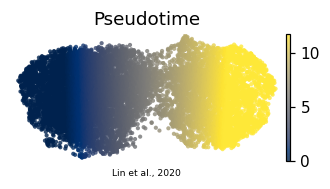

In [8]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Lin et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')